# Deconvolution without the six selected genes

Companion to [gene_interactions_interpretation.ipynb](gene_interactions_interpretation.ipynb).

**Question:** does the SPI1–MNDA–LYZ signal still track estimated myeloid RNA contributions when all six XGBoost genes are excluded from deconvolution?

Rerun BayesPrism twice for each of the 251 participants: baseline, and after excluding **GBP5, AHNAK, JMJD1C, MNDA, LYZ and SPI1**. Reuse the selected model's expression signal; do not refit the classifier or select genes again.

The results below are a matched sensitivity analysis, not a replacement for the manuscript's estimates.

**Shared-node resource budget:** 8 single-threaded workers on a server with 32 physical cores / 64 hardware threads. The current execution uses the user service `cfrna-deconvolution`, constrained to CPUs 8–15, an aggregate 8-CPU quota, 32 GiB of memory, and nice level 10. Thread-library limits are 1. These limits apply to the notebook kernel, R master, and all workers together. The service stops its entire process group on failure or cancellation.

Check execution with `systemctl --user status cfrna-deconvolution`; stop it with `systemctl --user stop cfrna-deconvolution`. The prior 64-worker run was stopped before any fits completed. The prepared reference cache is reused; fitted pairs are checkpointed in batches of eight. Results below are available only after successful completion.

## 1. Method and inputs

The exact reference filenames from the original pipeline were recovered in its local archive: **9,834 Tabula Sapiens cells, with 41 collapsed cell types**. This notebook reads those files directly. The all-gene branch of the repository's BayesPrism script supplies the cleanup settings. The historical package version and the precise branch that produced `discovery_cell_types.tsv` are not recorded, so a fresh baseline is essential.

Both reruns use BayesPrism **2.2.3**, the same cells, labels, raw counts, gene cleanup, per-sample fitting, MAP reference update, seed 123, and default 1,000-iteration initial/final Gibbs chains (500 burn-in, thinning 2). Bulk outliers are fixed using the baseline count matrix before removing the six genes. Ensembl version suffixes are removed identically from reference and cfRNA IDs, with uniqueness checked: the archived reference has LYZ `.6` and SPI1 `.11`, whereas cfRNA has `.7` and `.12`. Exact version matching would already omit those two genes. This corrected fresh baseline therefore is not an exact historical reconstruction. Harmonization increases the shared gene set from 20,795 to 29,435 before per-sample outlier filtering. Only the six-gene removal differs between the two fresh runs. Cell-type sums are cached after cleanup; these are exactly the sums used internally by `new.prism`, not a substitute deconvolution method.

**Interpretation:** fractions estimate relative RNA-read contributions over the retained genes, not cell counts. Removing six genes slightly changes that denominator. Stable findings reduce direct reuse of these six genes, but shared RNA measurement, correlated genes, reference mismatch and uncertain source assignments remain. The reference does not model every TB-specific cellular state.

Sources: [original local pipeline](../cfRNA_fastq_pipeline/workflow/scripts/BayesP_deconovlution.R), [BayesPrism software and interpretation](https://github.com/Danko-Lab/BayesPrism), [BayesPrism paper](https://doi.org/10.1038/s43018-022-00356-3).

The expensive R calculation is cached with input hashes. A clean rerun requires R with BayesPrism 2.2.3, data.table and jsonlite; the local library and executable are configured below. The installed upstream source is pinned to commit `19052052a6f30833b27e2148294459b0ba2f923e`.

In [1]:
import hashlib
import json
import os
import subprocess
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import Markdown, display
from scipy.stats import spearmanr

current = Path.cwd().resolve()
REPOSITORY = next(path for path in [current, *current.parents]
                  if (path / "Files_For_Manuscript/counts.train.tsv").exists())
DATA = REPOSITORY / "Files_For_Manuscript"
REFERENCE = DATA / "gene_interactions_reference"
OUTPUT = REPOSITORY / "Figure_Output/Gene_Interactions/focused"
REFERENCE_COUNTS = Path("/workdir/cjl332/archives/clust1_old/cfrna/deconvolution/validation/simulation_testing/references/tabsap_subCells-allGenes_thresh-100000.COUNTS.csv")
REFERENCE_METADATA = REFERENCE_COUNTS.with_name(REFERENCE_COUNTS.name.replace("COUNTS", "META"))
RSCRIPT = Path("/programs/R-4.3.2/bin/Rscript")
R_LIBRARY = Path.home() / ".local/lib/R/cfrna-bayesprism-4.3"
SPLITS = {"train": "Training", "test": "Test", "val": "Validation"}
SIGNATURE = ["GBP5", "AHNAK", "JMJD1C", "MNDA", "LYZ", "SPI1"]
SEED = 123
# Explicit shared-node budget; CPU availability is not permission to use every core.
WORKERS = min(8, len(os.sched_getaffinity(0)))

sns.set_theme(style="ticks", context="paper")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42})

def save_figure(figure, name):
    for extension in ["png", "pdf"]:
        figure.savefig(OUTPUT / f"deconvolution_{name}.{extension}", bbox_inches="tight")

def file_hash(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

In [2]:
analysis = pd.read_csv(OUTPUT / "myeloid_analysis_inputs.csv", index_col="sample_id")
original_fractions = pd.read_csv(DATA / "discovery_cell_types.tsv", sep="\t", index_col="sample_id").loc[analysis.index]
groups = json.loads((OUTPUT / "myeloid_group_definitions.json").read_text())["primary"]
candidates = pd.read_csv(REFERENCE / "paper_input_audit/training_candidates.tsv", sep="\t")
signature_ids = candidates.set_index("gene_name").loc[SIGNATURE, "gene_id"].tolist()
assert len(analysis) == 251 and analysis.index.is_unique
assert len(set(signature_ids)) == 6
assert REFERENCE_COUNTS.is_file() and REFERENCE_METADATA.is_file()

input_paths = [REFERENCE_COUNTS, REFERENCE_METADATA,
               *[DATA / f"counts.{split}.tsv" for split in SPLITS]]
settings = {"input_sha256": {str(path): file_hash(path) for path in input_paths},
            "BayesPrism": "2.2.3", "upstream_commit": "19052052a6f30833b27e2148294459b0ba2f923e",
            "excluded_gene_ids": signature_ids, "excluded_gene_names": SIGNATURE,
            "seed": SEED, "chain_length": 1000, "burn_in": 500, "thinning": 2,
            "reference_cleanup": ["Rb", "Mrp", "other_Rb", "chrM", "MALAT1", "chrX", "chrY"],
            "minimum_expressing_cells": 5, "outlier_cut": 0.01, "outlier_fraction": 0.1,
            "gene_identifier_rule": "Remove trailing Ensembl version suffix; require unique stable IDs",
            "fit_scope": "Each sample independently; all-gene branch; frozen baseline outlier filter"}
configuration = dict(settings, repository=str(REPOSITORY),
                     reference_counts=str(REFERENCE_COUNTS), reference_metadata=str(REFERENCE_METADATA),
                     r_library=str(R_LIBRARY), workers=WORKERS)
display(pd.DataFrame({"Excluded gene": SIGNATURE, "Ensembl ID": signature_ids}))

,Excluded gene,Ensembl ID
0,GBP5,ENSG00000154451.14
1,AHNAK,ENSG00000124942.14
2,JMJD1C,ENSG00000171988.19
3,MNDA,ENSG00000163563.8
4,LYZ,ENSG00000090382.7
5,SPI1,ENSG00000066336.12


## 2. Prepare the original reference once

The R code is kept here so the complete analysis is reviewable in the notebook. It uses the official package's cleanup and sums raw reference counts within the original cell-type labels. Hash-matched caches make repeated notebook execution quick.

In [3]:
r_setup = r"""
arguments <- commandArgs(trailingOnly=TRUE)
configuration <- jsonlite::read_json(arguments[1], simplifyVector=TRUE)
.libPaths(c(configuration$r_library, .libPaths()))
suppressPackageStartupMessages(library(BayesPrism))
suppressPackageStartupMessages(library(data.table))
stopifnot(as.character(packageVersion("BayesPrism")) == configuration$BayesPrism)
repository <- configuration$repository
reference_directory <- file.path(repository, "Files_For_Manuscript/gene_interactions_reference")
output_directory <- file.path(repository, "Figure_Output/Gene_Interactions/focused")
reference_cache <- file.path(reference_directory, "deconvolution_reference.rds")
result_cache <- file.path(reference_directory, "deconvolution_results.rds")
progress_path <- file.path(output_directory, "deconvolution_progress.log")

if (file.exists(reference_cache)) {
    reference_data <- readRDS(reference_cache)
    stopifnot(identical(reference_data$fingerprint, configuration$fingerprint))
} else {
    reference_table <- fread(configuration$reference_counts, nThread=4)
    reference_metadata <- fread(configuration$reference_metadata)
    stopifnot(identical(reference_table[[1]], reference_metadata$cell_id))
    cell_ids <- reference_table[[1]]
    reference_table[[1]] <- NULL
    reference_matrix <- as.matrix(reference_table)
    rownames(reference_matrix) <- cell_ids
    reference_matrix <- cleanup.genes(
        reference_matrix, input.type="count.matrix", species="hs",
        gene.group=configuration$reference_cleanup, exp.cells=5)
    labels <- reference_metadata$cell_type_collapsed
    reference_data <- list(
        fingerprint=configuration$fingerprint,
        reference=BayesPrism:::collapse(reference_matrix, labels),
        cell_counts=table(labels), gene_count=ncol(reference_matrix))
    saveRDS(reference_data, reference_cache)
    rm(reference_table, reference_matrix)
    gc()
}
reference_profile <- reference_data$reference
colnames(reference_profile) <- sub("\\.[0-9]+$", "", colnames(reference_profile))
stopifnot(!anyDuplicated(colnames(reference_profile)))
stopifnot(nrow(reference_profile) == 41)
write.csv(data.frame(cell_type=names(reference_data$cell_counts),
                     reference_cells=as.integer(reference_data$cell_counts)),
          file.path(output_directory, "deconvolution_reference_cell_counts.csv"), row.names=FALSE)

read_counts <- function(split) {
    path <- file.path(repository, paste0("Files_For_Manuscript/counts.", split, ".tsv"))
    as.matrix(read.delim(path, row.names=1, check.names=FALSE))
}
counts_by_split <- lapply(c("train", "test", "val"), read_counts)
stopifnot(all(vapply(counts_by_split, function(counts) identical(rownames(counts), rownames(counts_by_split[[1]])), logical(1))))
mixtures <- t(do.call(cbind, counts_by_split))
stopifnot(!anyDuplicated(rownames(mixtures)), nrow(mixtures) == 251)
colnames(mixtures) <- sub("\\.[0-9]+$", "", colnames(mixtures))
excluded_ids <- sub("\\.[0-9]+$", "", configuration$excluded_gene_ids)
stopifnot(!anyDuplicated(colnames(mixtures)))
stopifnot(all(excluded_ids %in% colnames(reference_profile)), all(excluded_ids %in% colnames(mixtures)))
"""

## 3. Run the matched baseline and gene exclusion

Each participant is fitted independently, preserving the original workflow's scope. A worker uses one CPU and one private R temporary directory. The default Gibbs chain lengths and optimizer are unchanged. Successful batches are checkpointed; an error is raised rather than silently dropping a participant.

For each fit, save final fractions, the retained-gene count, the signature genes actually present, and the package's posterior coefficient of variation. The latter describes within-chain posterior uncertainty and is not a convergence diagnostic or a standard error for the baseline–exclusion difference. Upstream `run.prism` does not expose optimizer convergence codes; successful execution is not a convergence certificate.

In [4]:
r_deconvolution = r"""
fit_sample <- function(sample_id) {
    mixture <- mixtures[sample_id, , drop=FALSE]
    # Fix the original per-sample outlier filter before either fit.
    log_output <- capture.output({
        mixture <- BayesPrism:::filter.bulk.outlier(mixture, outlier.cut=0.01, outlier.fraction=0.1)
    })
    fitted_variants <- lapply(c("baseline", "excluded"), function(variant) {
        retained <- if (variant == "baseline") colnames(reference_profile) else setdiff(colnames(reference_profile), excluded_ids)
        fit_log <- capture.output({
            prism <- new.prism(
                reference=reference_profile[, retained, drop=FALSE], input.type="GEP",
                mixture=mixture, cell.type.labels=rownames(reference_profile),
                cell.state.labels=rownames(reference_profile), key=NULL,
                outlier.cut=1, outlier.fraction=0.1)
            present_signature <- intersect(colnames(prism@mixture), excluded_ids)
            if (variant == "baseline") stopifnot(setequal(present_signature, excluded_ids))
            if (variant == "excluded") stopifnot(length(present_signature) == 0)
            fit <- run.prism(prism, n.cores=1,
                             gibbs.control=list(seed=configuration$seed))
        })
        fractions <- get.fraction(fit, which.theta="final", state.or.type="type")
        stopifnot(all(is.finite(fractions)), all(fractions >= 0), abs(sum(fractions)-1) < 1e-8)
        cat(sample_id, variant, "complete", format(Sys.time()), "\n", file=progress_path, append=TRUE)
        list(fractions=fractions, posterior_cv=fit@posterior.theta_f@theta.cv,
             genes=ncol(prism@mixture), signature_genes=present_signature,
             log=c(log_output, fit_log))
    })
    names(fitted_variants) <- c("baseline", "excluded")
    stopifnot(fitted_variants$baseline$genes - fitted_variants$excluded$genes ==
                  length(fitted_variants$baseline$signature_genes))
    fitted_variants
}

results <- if (file.exists(result_cache)) readRDS(result_cache) else list(fingerprint=configuration$fingerprint, samples=list())
stopifnot(identical(results$fingerprint, configuration$fingerprint))
remaining_samples <- setdiff(rownames(mixtures), names(results$samples))
if (length(remaining_samples)) {
    writeLines(character(), progress_path)
    Sys.setenv(R_LIBS_USER=configuration$r_library,
               OPENBLAS_NUM_THREADS=1, OMP_NUM_THREADS=1, MKL_NUM_THREADS=1)
    cluster <- parallel::makeCluster(min(configuration$workers, length(remaining_samples)))
    parallel::clusterEvalQ(cluster, suppressPackageStartupMessages(library(BayesPrism)))
    parallel::clusterExport(cluster, c("reference_profile", "mixtures", "excluded_ids", "configuration", "fit_sample", "progress_path"))
    batches <- split(remaining_samples, ceiling(seq_along(remaining_samples)/configuration$workers))
    for (batch in batches) {
        started <- Sys.time()
        batch_results <- parallel::parLapply(cluster, batch, fit_sample)
        results$samples[batch] <- batch_results
        saveRDS(results, result_cache)
        cat(length(results$samples), "of", nrow(mixtures), "paired samples complete; batch minutes:",
            round(as.numeric(difftime(Sys.time(), started, units="mins")), 1), "\n")
        flush.console()
    }
    parallel::stopCluster(cluster)
}

for (variant in c("baseline", "excluded")) {
    fractions <- do.call(rbind, lapply(results$samples[rownames(mixtures)], function(sample) sample[[variant]]$fractions))
    colnames(fractions) <- make.names(colnames(fractions))
    write.csv(fractions, file.path(output_directory, paste0("deconvolution_", variant, "_fractions.csv")))
}
diagnostics <- do.call(rbind, lapply(names(results$samples), function(sample_id) {
    do.call(rbind, lapply(c("baseline", "excluded"), function(variant) {
        fit <- results$samples[[sample_id]][[variant]]
        data.frame(sample_id=sample_id, variant=variant, retained_genes=fit$genes,
                   signature_genes=paste(fit$signature_genes, collapse=","),
                   signature_gene_count=length(fit$signature_genes),
                   median_posterior_cv=median(fit$posterior_cv),
                   maximum_posterior_cv=max(fit$posterior_cv),
                   optimizer_status="not exposed by run.prism")
    }))
}))
write.csv(diagnostics, file.path(output_directory, "deconvolution_fit_diagnostics.csv"), row.names=FALSE)
capture.output(sessionInfo(), file=file.path(output_directory, "deconvolution_R_session.txt"))
cat("Completed", length(results$samples), "matched pairs.\n")
"""

In [5]:
# The script is temporary; all source code remains in the two cells above.
settings["r_code_sha256"] = hashlib.sha256((r_setup + r_deconvolution).encode()).hexdigest()
fingerprint = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()
configuration.update(settings, fingerprint=fingerprint)
(REFERENCE / "deconvolution_settings.json").write_text(json.dumps(configuration, indent=2))
log_path = OUTPUT / "deconvolution_run.log"
with tempfile.TemporaryDirectory(prefix="cfrna-deconvolution-") as temporary:
    script_path = Path(temporary) / "deconvolution.R"
    script_path.write_text(r_setup + "\n" + r_deconvolution)
    environment = dict(os.environ, R_LIBS_USER=str(R_LIBRARY), OPENBLAS_NUM_THREADS="1",
                       OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
    with log_path.open("w") as log:
        subprocess.run([str(RSCRIPT), str(script_path), str(REFERENCE / "deconvolution_settings.json")],
                       env=environment, stdout=log, stderr=subprocess.STDOUT, check=True)
print(log_path.read_text().splitlines()[-1])

Completed 251 matched pairs.


## 4. Do estimated RNA fractions change?

First compare the two fresh runs. The manuscript table is an additional provenance check; disagreement with that table can reflect an unrecorded historical gene-filter branch or package version. A small baseline–exclusion difference must not be interpreted as an exact zero: both estimates use Monte Carlo sampling.

Cell type,Mean |change| (pp),Max |change| (pp),ρ: baseline vs excluded,ρ: manuscript vs baseline
Monocyte,0.3936,2.9490,0.9968,0.9682
T.Cell,0.3111,1.5330,0.9941,0.7908
NK.Cell,0.3106,1.4607,0.9975,0.8811
Myeloid.progenitor,0.2716,0.8589,0.9997,0.9759
Platelet,0.1782,0.6874,1.0000,0.9982
Thymocyte,0.1543,0.9334,0.9753,0.8479
B.cell,0.1538,0.6324,0.9992,0.9600
Intestinal.tuft.cell,0.1185,0.4032,0.9993,0.7694
Schwann.cell,0.0829,0.3844,0.9927,0.8796
neutrophil,0.0631,0.7864,0.9897,0.9730


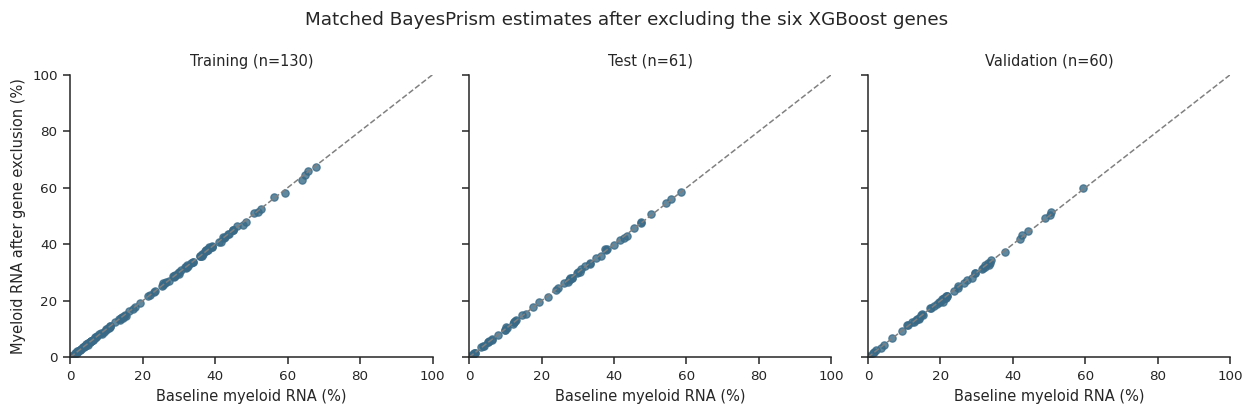

In [6]:
fractions = {"Manuscript": original_fractions}
for label, filename in [("Fresh baseline", "baseline"), ("Six genes excluded", "excluded")]:
    frame = pd.read_csv(OUTPUT / f"deconvolution_{filename}_fractions.csv", index_col=0)
    assert frame.index.is_unique and set(frame.columns) == set(original_fractions.columns)
    fractions[label] = frame.loc[analysis.index, original_fractions.columns]
    assert np.isfinite(fractions[label]).all().all()
    np.testing.assert_allclose(fractions[label].sum(axis=1), 1, atol=1e-8)

baseline = fractions["Fresh baseline"]
excluded = fractions["Six genes excluded"]
absolute_change = (excluded - baseline).abs()
stability = pd.DataFrame({
    "cell_type": baseline.columns,
    "mean_absolute_change_percentage_points": 100 * absolute_change.mean(),
    "maximum_absolute_change_percentage_points": 100 * absolute_change.max(),
    "spearman_baseline_vs_excluded": [spearmanr(baseline[cell], excluded[cell]).statistic for cell in baseline],
    "spearman_manuscript_vs_baseline": [spearmanr(original_fractions[cell], baseline[cell]).statistic for cell in baseline],
}).reset_index(drop=True)
stability.to_csv(OUTPUT / "deconvolution_fraction_stability.csv", index=False)
grouped_fractions = {label: pd.DataFrame({group: frame[members].sum(axis=1) for group, members in groups.items()})
                     for label, frame in fractions.items()}
for grouped in grouped_fractions.values():
    assert (grouped > 0).all().all()
    np.testing.assert_allclose(grouped.sum(axis=1), 1, atol=1e-8)

display(stability.sort_values("mean_absolute_change_percentage_points", ascending=False).head(12)
        .rename(columns={"cell_type": "Cell type",
                         "mean_absolute_change_percentage_points": "Mean |change| (pp)",
                         "maximum_absolute_change_percentage_points": "Max |change| (pp)",
                         "spearman_baseline_vs_excluded": "ρ: baseline vs excluded",
                         "spearman_manuscript_vs_baseline": "ρ: manuscript vs baseline"})
        .style.format(precision=4).hide(axis="index"))
figure, axes = plt.subplots(1, 3, figsize=(11.5, 3.8), sharex=True, sharey=True)
for axis, split in zip(axes, SPLITS):
    samples = analysis.index[analysis.split.eq(split)]
    x = 100 * grouped_fractions["Fresh baseline"].loc[samples, "myeloid"]
    y = 100 * grouped_fractions["Six genes excluded"].loc[samples, "myeloid"]
    axis.scatter(x, y, color="#386A87", s=23, alpha=0.8)
    axis.plot([0, 100], [0, 100], "--", color="0.5", lw=1)
    axis.set(title=f"{SPLITS[split]} (n={len(samples)})", xlabel="Baseline myeloid RNA (%)",
             xlim=(0, 100), ylim=(0, 100))
axes[0].set_ylabel("Myeloid RNA after gene exclusion (%)")
figure.suptitle("Matched BayesPrism estimates after excluding the six XGBoost genes")
figure.tight_layout()
save_figure(figure, "fraction_stability")
plt.show()

## 5. Does the signal–myeloid relationship persist?

Reuse the fixed positive, equally weighted mean of the training-standardized SPI1, MNDA and LYZ expression from the interpretation notebook. Report Spearman correlations by split, and the correlation of ranked residuals after controlling for cohort and TB status. These are descriptive correlations, not independent validation of the selected genes.

deconvolution,Fresh baseline,Manuscript,Six genes excluded
split,,,
train,0.778,0.749,0.773
test,0.782,0.759,0.777
val,0.746,0.714,0.745


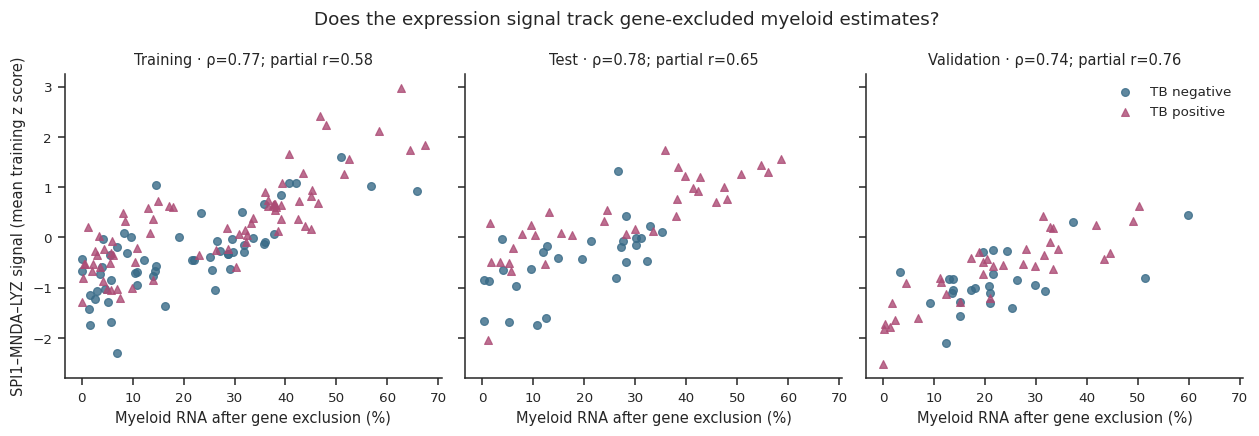

In [7]:
def make_design(frame, columns):
    design = frame[[column for column in columns if column != "cohort"]].astype(float).copy()
    if "cohort" in columns:
        design = design.join(pd.get_dummies(frame.cohort, prefix="cohort", drop_first=True, dtype=float))
    design = sm.add_constant(design, has_constant="add")
    assert np.linalg.matrix_rank(design) == design.shape[1]
    return design

correlation_rows = []
association_rows = []
for label, grouped in grouped_fractions.items():
    frame = analysis[["split", "cohort", "tb_positive", "three_gene_signal"]].copy()
    frame["myeloid_fraction"] = grouped.myeloid
    composition_columns = []
    for group in grouped.columns.drop("other"):
        column = f"log_{group}_vs_other"
        frame[column] = np.log(grouped[group] / grouped.other)
        composition_columns.append(column)
    for split, subset in frame.groupby("split", sort=False):
        nuisance = make_design(subset, ["cohort", "tb_positive"])
        ranked = subset[["three_gene_signal", "myeloid_fraction"]].rank()
        residuals = ranked.to_numpy() - nuisance @ np.linalg.lstsq(nuisance, ranked, rcond=None)[0]
        correlation_rows.append({"split": split, "deconvolution": label, "n": len(subset),
            "spearman_rho": spearmanr(subset.three_gene_signal, subset.myeloid_fraction).statistic,
            "partial_rank_r": np.corrcoef(np.asarray(residuals).T)[0, 1]})
        design = make_design(subset, ["tb_positive", "cohort", *composition_columns])
        fit = sm.OLS(subset.three_gene_signal, design).fit(cov_type="HC3", use_t=True)
        lower, upper = fit.conf_int().loc["tb_positive"]
        association_rows.append({"split": split, "deconvolution": label, "n": len(subset),
            "tb_difference": fit.params.tb_positive, "ci_lower": lower, "ci_upper": upper,
            "nominal_p": fit.pvalues.tb_positive, "design_condition_number": np.linalg.cond(design)})
correlations = pd.DataFrame(correlation_rows)
associations = pd.DataFrame(association_rows)
correlations.to_csv(OUTPUT / "deconvolution_signal_correlations.csv", index=False)
associations.to_csv(OUTPUT / "deconvolution_tb_associations.csv", index=False)
display(correlations.pivot(index="split", columns="deconvolution", values="spearman_rho")
        .reindex(SPLITS).style.format(precision=3))

figure, axes = plt.subplots(1, 3, figsize=(11.5, 4.0), sharex=True, sharey=True)
for axis, split in zip(axes, SPLITS):
    subset = analysis.loc[analysis.split.eq(split)]
    x = 100 * grouped_fractions["Six genes excluded"].loc[subset.index, "myeloid"]
    for tb, color in [(0, "#386A87"), (1, "#AC4B75")]:
        selected = subset.tb_positive.eq(tb)
        axis.scatter(x[selected], subset.loc[selected, "three_gene_signal"],
                     c=color, marker="^" if tb else "o", s=26, alpha=0.8, label=f"TB {'positive' if tb else 'negative'}")
    row = correlations.loc[correlations.split.eq(split) & correlations.deconvolution.eq("Six genes excluded")].iloc[0]
    axis.set(title=f"{SPLITS[split]} · ρ={row.spearman_rho:.2f}; partial r={row.partial_rank_r:.2f}",
             xlabel="Myeloid RNA after gene exclusion (%)")
axes[0].set_ylabel("SPI1–MNDA–LYZ signal (mean training z score)")
axes[-1].legend(frameon=False)
figure.suptitle("Does the expression signal track gene-excluded myeloid estimates?")
figure.tight_layout()
save_figure(figure, "signal_correlation")
plt.show()

## 6. Does the composition-adjusted TB association persist?

Fit `signal ~ TB + cohort + log(myeloid/other) + log(lymphoid/other) + log(erythroid–platelet/other)` separately in each split. The coefficient is the conditional TB-positive minus TB-negative difference in the expression signal. The comparison changes only the composition estimates.

Intervals are 95% HC3 robust, residual-df t intervals. They do not propagate deconvolution uncertainty, multiple testing or previous gene selection. This remains an association analysis; it cannot separate RNA release, turnover, disease-mediated source shifts or cell-intrinsic expression mechanistically.

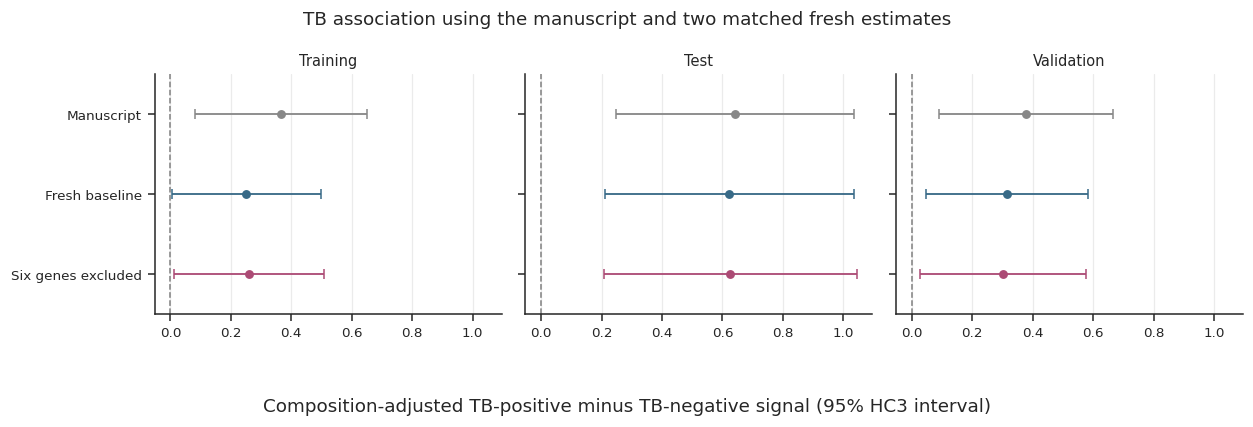

split,deconvolution,n,tb_difference,ci_lower,ci_upper
train,Manuscript,130,0.366,0.082,0.650
test,Manuscript,61,0.642,0.248,1.036
val,Manuscript,60,0.378,0.089,0.666
train,Fresh baseline,130,0.251,0.004,0.499
test,Fresh baseline,61,0.623,0.211,1.034
val,Fresh baseline,60,0.314,0.046,0.582
train,Six genes excluded,130,0.259,0.010,0.508
test,Six genes excluded,61,0.626,0.207,1.044
val,Six genes excluded,60,0.301,0.026,0.576


In [8]:
labels = list(fractions)
colors = {"Manuscript": "#888888", "Fresh baseline": "#386A87", "Six genes excluded": "#AC4B75"}
figure, axes = plt.subplots(1, 3, figsize=(11.5, 3.8), sharex=True, sharey=True)
for axis, split in zip(axes, SPLITS):
    rows = associations.loc[associations.split.eq(split)].set_index("deconvolution").loc[labels]
    for position, (label, row) in enumerate(rows.iterrows()):
        axis.errorbar(row.tb_difference, position,
                      xerr=[[row.tb_difference-row.ci_lower], [row.ci_upper-row.tb_difference]],
                      fmt="o", color=colors[label], capsize=3)
    axis.axvline(0, color="0.5", ls="--", lw=1)
    axis.set(title=SPLITS[split], yticks=range(len(labels)), yticklabels=labels,
             ylim=(len(labels)-0.5, -0.5))
    axis.grid(axis="x", color="0.92")
figure.supxlabel("Composition-adjusted TB-positive minus TB-negative signal (95% HC3 interval)")
figure.suptitle("TB association using the manuscript and two matched fresh estimates")
figure.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(figure, "tb_association")
plt.show()
display(associations[["split", "deconvolution", "n", "tb_difference", "ci_lower", "ci_upper"]]
        .style.format(precision=3).hide(axis="index"))

## 7. Read the matched sensitivity analysis

Judge the fresh baseline against the fresh excluded-gene run first. The manuscript comparison checks historical agreement, not the exclusion effect. Stable correlations and adjusted associations would argue that direct inclusion of these six genes is not the main source of the observed relationship. They would **not establish independent cell-composition measurement or a cell-intrinsic TB response**.

If exclusion materially changes results, investigate the source-specific shifts and reference identifiability before assigning biological mechanisms. Even small numerical changes contain Monte Carlo variability; this analysis is not a formal test of equivalence.

In [9]:
takeaways = []
for split in SPLITS:
    samples = analysis.index[analysis.split.eq(split)]
    change = 100 * (grouped_fractions["Six genes excluded"].loc[samples, "myeloid"] -
                    grouped_fractions["Fresh baseline"].loc[samples, "myeloid"])
    correlation = correlations.loc[correlations.split.eq(split) & correlations.deconvolution.eq("Six genes excluded")].iloc[0]
    association = associations.loc[associations.split.eq(split) & associations.deconvolution.eq("Six genes excluded")].iloc[0]
    takeaways.append(f"- **{SPLITS[split]}:** median absolute myeloid shift **{change.abs().median():.3f} percentage points**; "
                     f"gene-excluded signal correlation **ρ={correlation.spearman_rho:.3f}**; "
                     f"adjusted TB difference **{association.tb_difference:.3f}** "
                     f"(95% CI {association.ci_lower:.3f} to {association.ci_upper:.3f}).")
display(Markdown("**Observed results:**\n\n" + "\n".join(takeaways)))
provenance = dict(settings, fingerprint=fingerprint, samples=len(analysis),
                 expression_signal_source=str(OUTPUT / "myeloid_analysis_inputs.csv"),
                 expression_signal_sha256=file_hash(OUTPUT / "myeloid_analysis_inputs.csv"),
                 figures=["fraction_stability", "signal_correlation", "tb_association"])
(OUTPUT / "deconvolution_provenance.json").write_text(json.dumps(provenance, indent=2))
print("Completed all 251 paired fits and saved the comparison tables and figures.")

**Observed results:**

- **Training:** median absolute myeloid shift **0.135 percentage points**; gene-excluded signal correlation **ρ=0.773**; adjusted TB difference **0.259** (95% CI 0.010 to 0.508).
- **Test:** median absolute myeloid shift **0.167 percentage points**; gene-excluded signal correlation **ρ=0.777**; adjusted TB difference **0.626** (95% CI 0.207 to 1.044).
- **Validation:** median absolute myeloid shift **0.214 percentage points**; gene-excluded signal correlation **ρ=0.745**; adjusted TB difference **0.301** (95% CI 0.026 to 0.576).

Completed all 251 paired fits and saved the comparison tables and figures.
